# 03. Global, Local, and Interaction TreeSHAP Explanations
## Partial Dependence Plots (PDP) & Accumulated Local Effects (ALE)


Here we analyze model explanations using TreeSHAP and compare PDP vs ALE to identify nonlinear impacts and handle feature correlations.


In [1]:
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd
import json
from IPython.display import Image, display

# Global feature importance
imp_df = pd.read_csv("results/shap/task_a_xgb_global_importance.csv")
imp_df.head(10)


,feature,mean_abs_shap,mean_signed_shap,family,normalized_share,rank
0,traffic_flow_hourly_est,0.541981,-0.143652,Traffic,0.427440,1
1,hour,0.133099,-0.034008,Time/Light,0.104970,2
2,solar_elevation_deg,0.123632,0.000217,Time/Light,0.097504,3
3,hour_of_week,0.076906,-0.008349,Time/Light,0.060653,4
4,day_of_week,0.066771,-0.009527,Time/Light,0.052659,5
5,month,0.061728,-0.003070,Time/Light,0.048682,6
6,temperature_2m,0.049526,-0.006925,Weather,0.039059,7
7,wind_gusts_10m,0.046648,-0.001547,Weather,0.036789,8
8,rolling_24h_precip,0.035452,-0.006646,Weather,0.027959,9
9,junction_detail,0.027284,-0.003124,Road,0.021518,10


### Global TreeSHAP Summary Plot
Features are grouped into Weather, Road, Traffic, and Time/Light families.


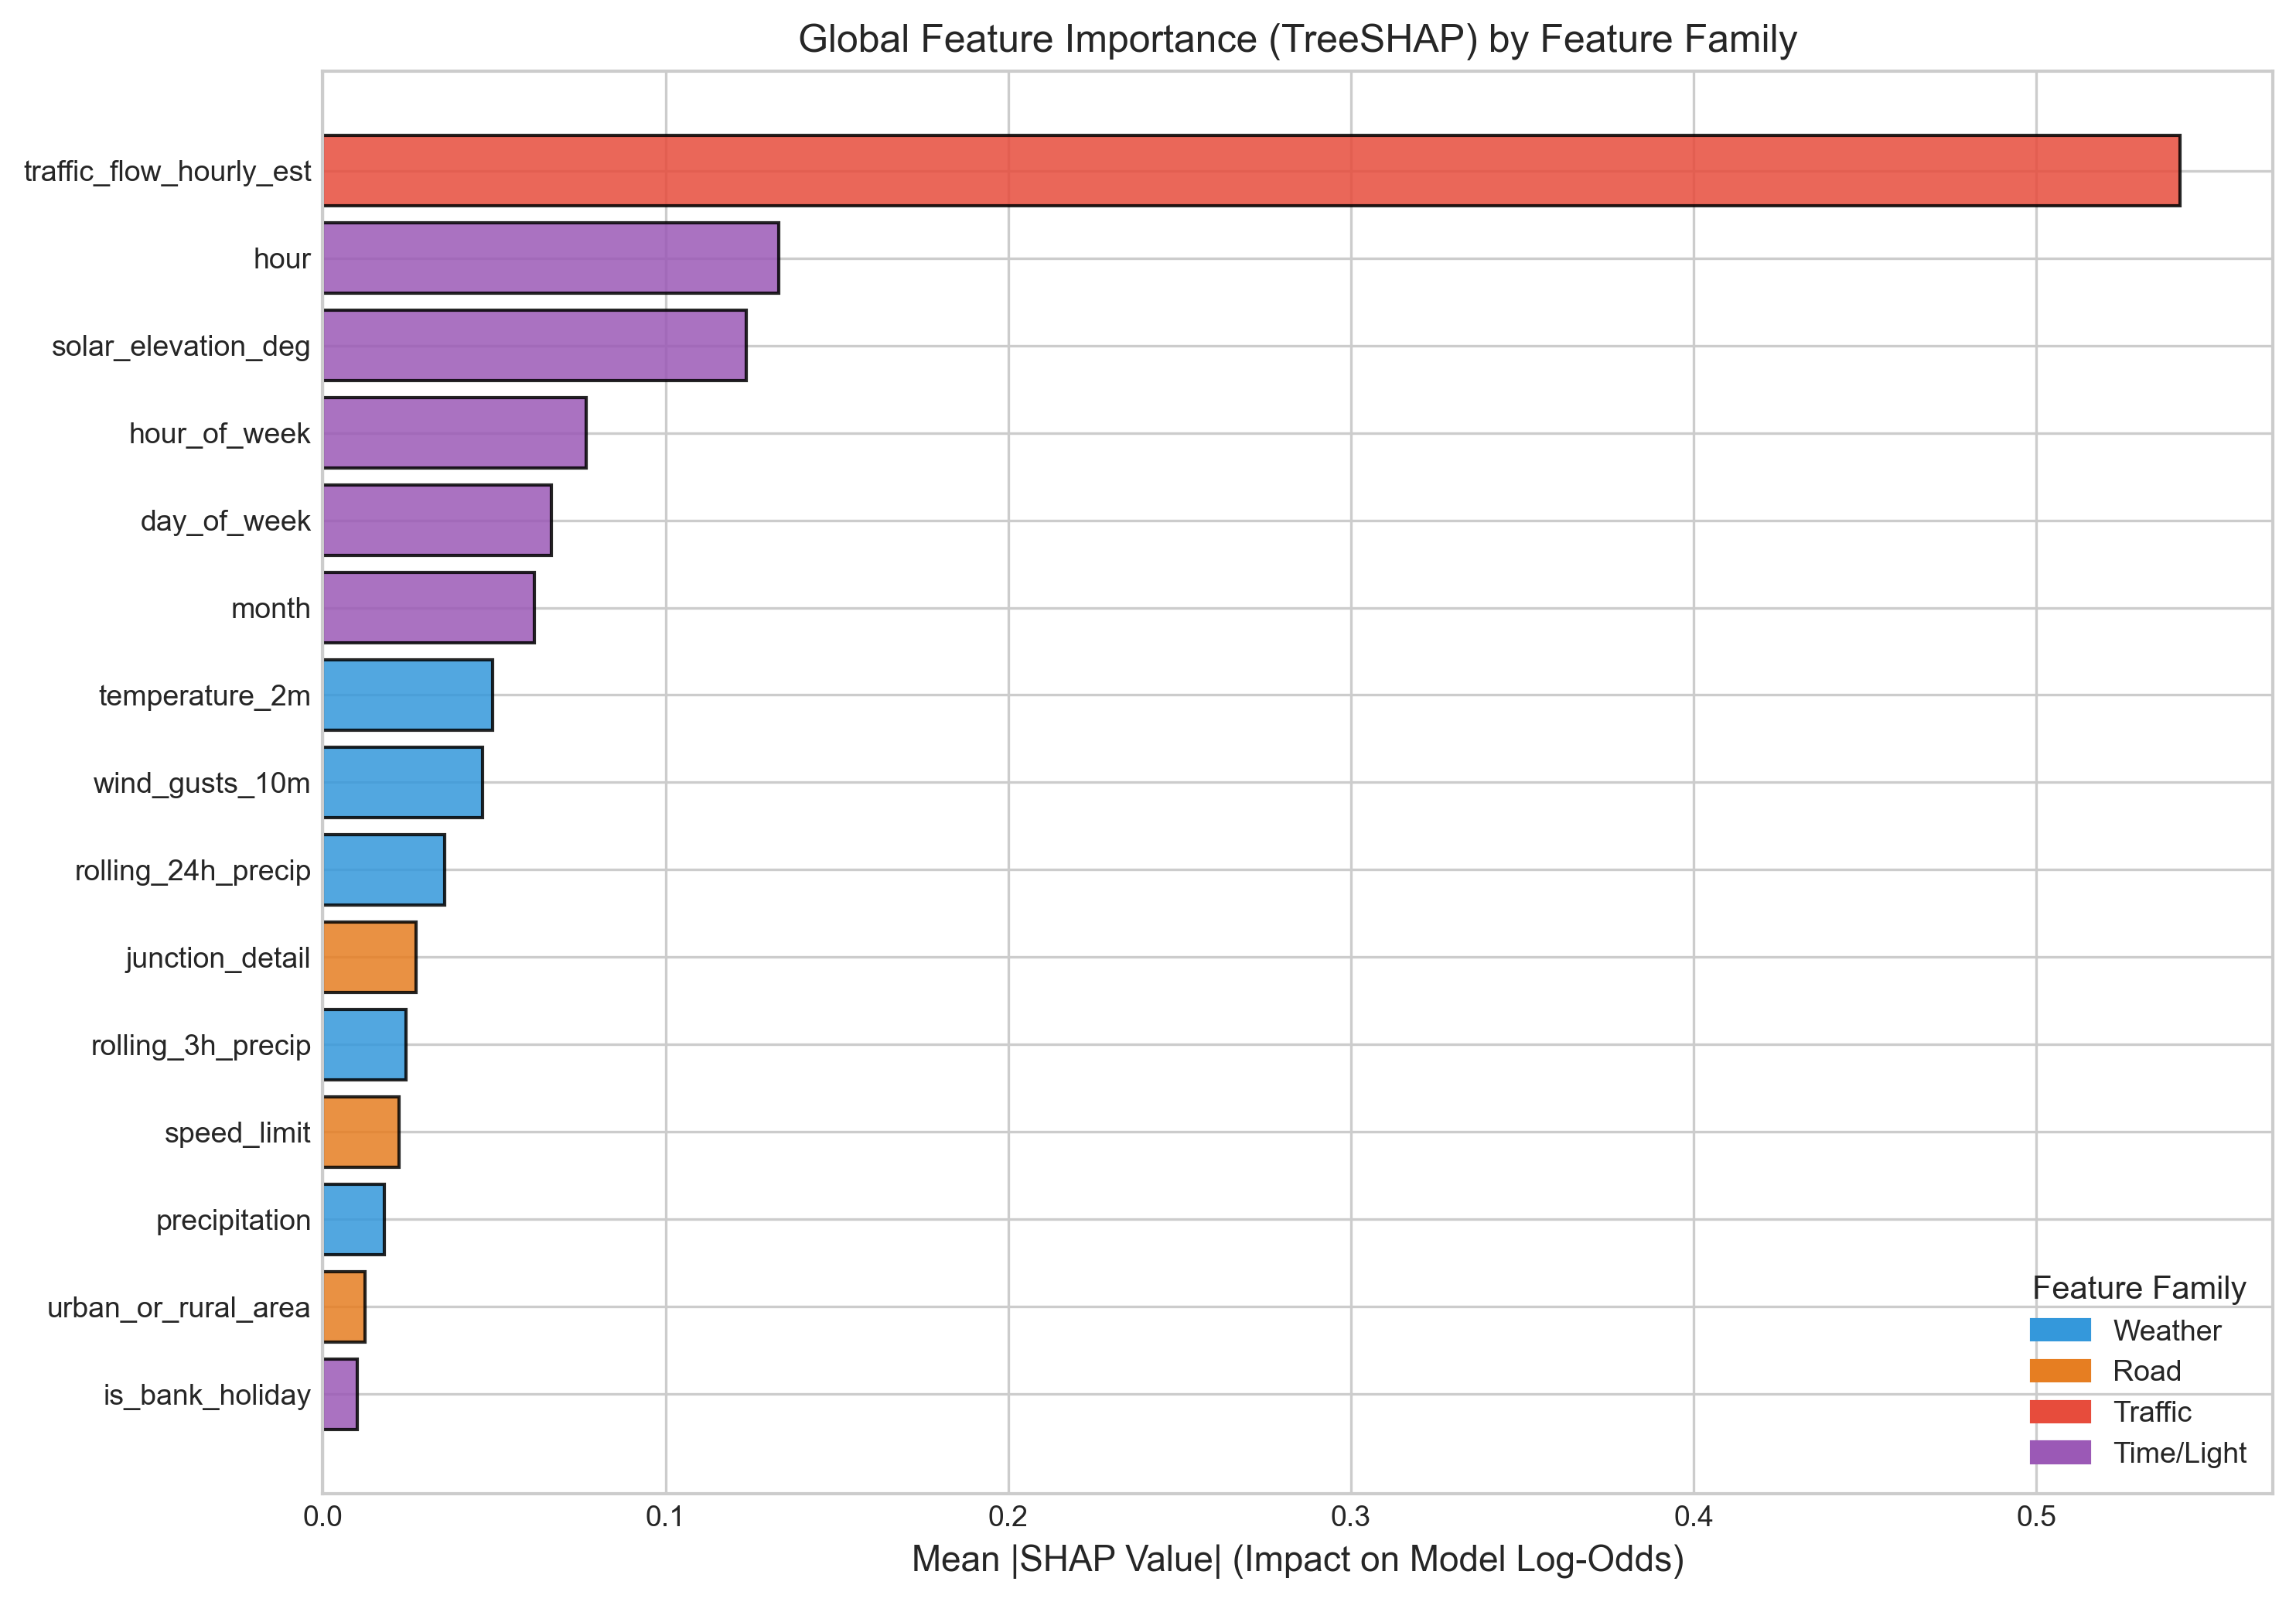

In [2]:
display(Image("figures/fig3_shap_global_summary.png"))


### Partial Dependence vs Accumulated Local Effects (ALE)
ALE isolates local feature effects without evaluating unrealistic off-manifold combinations.


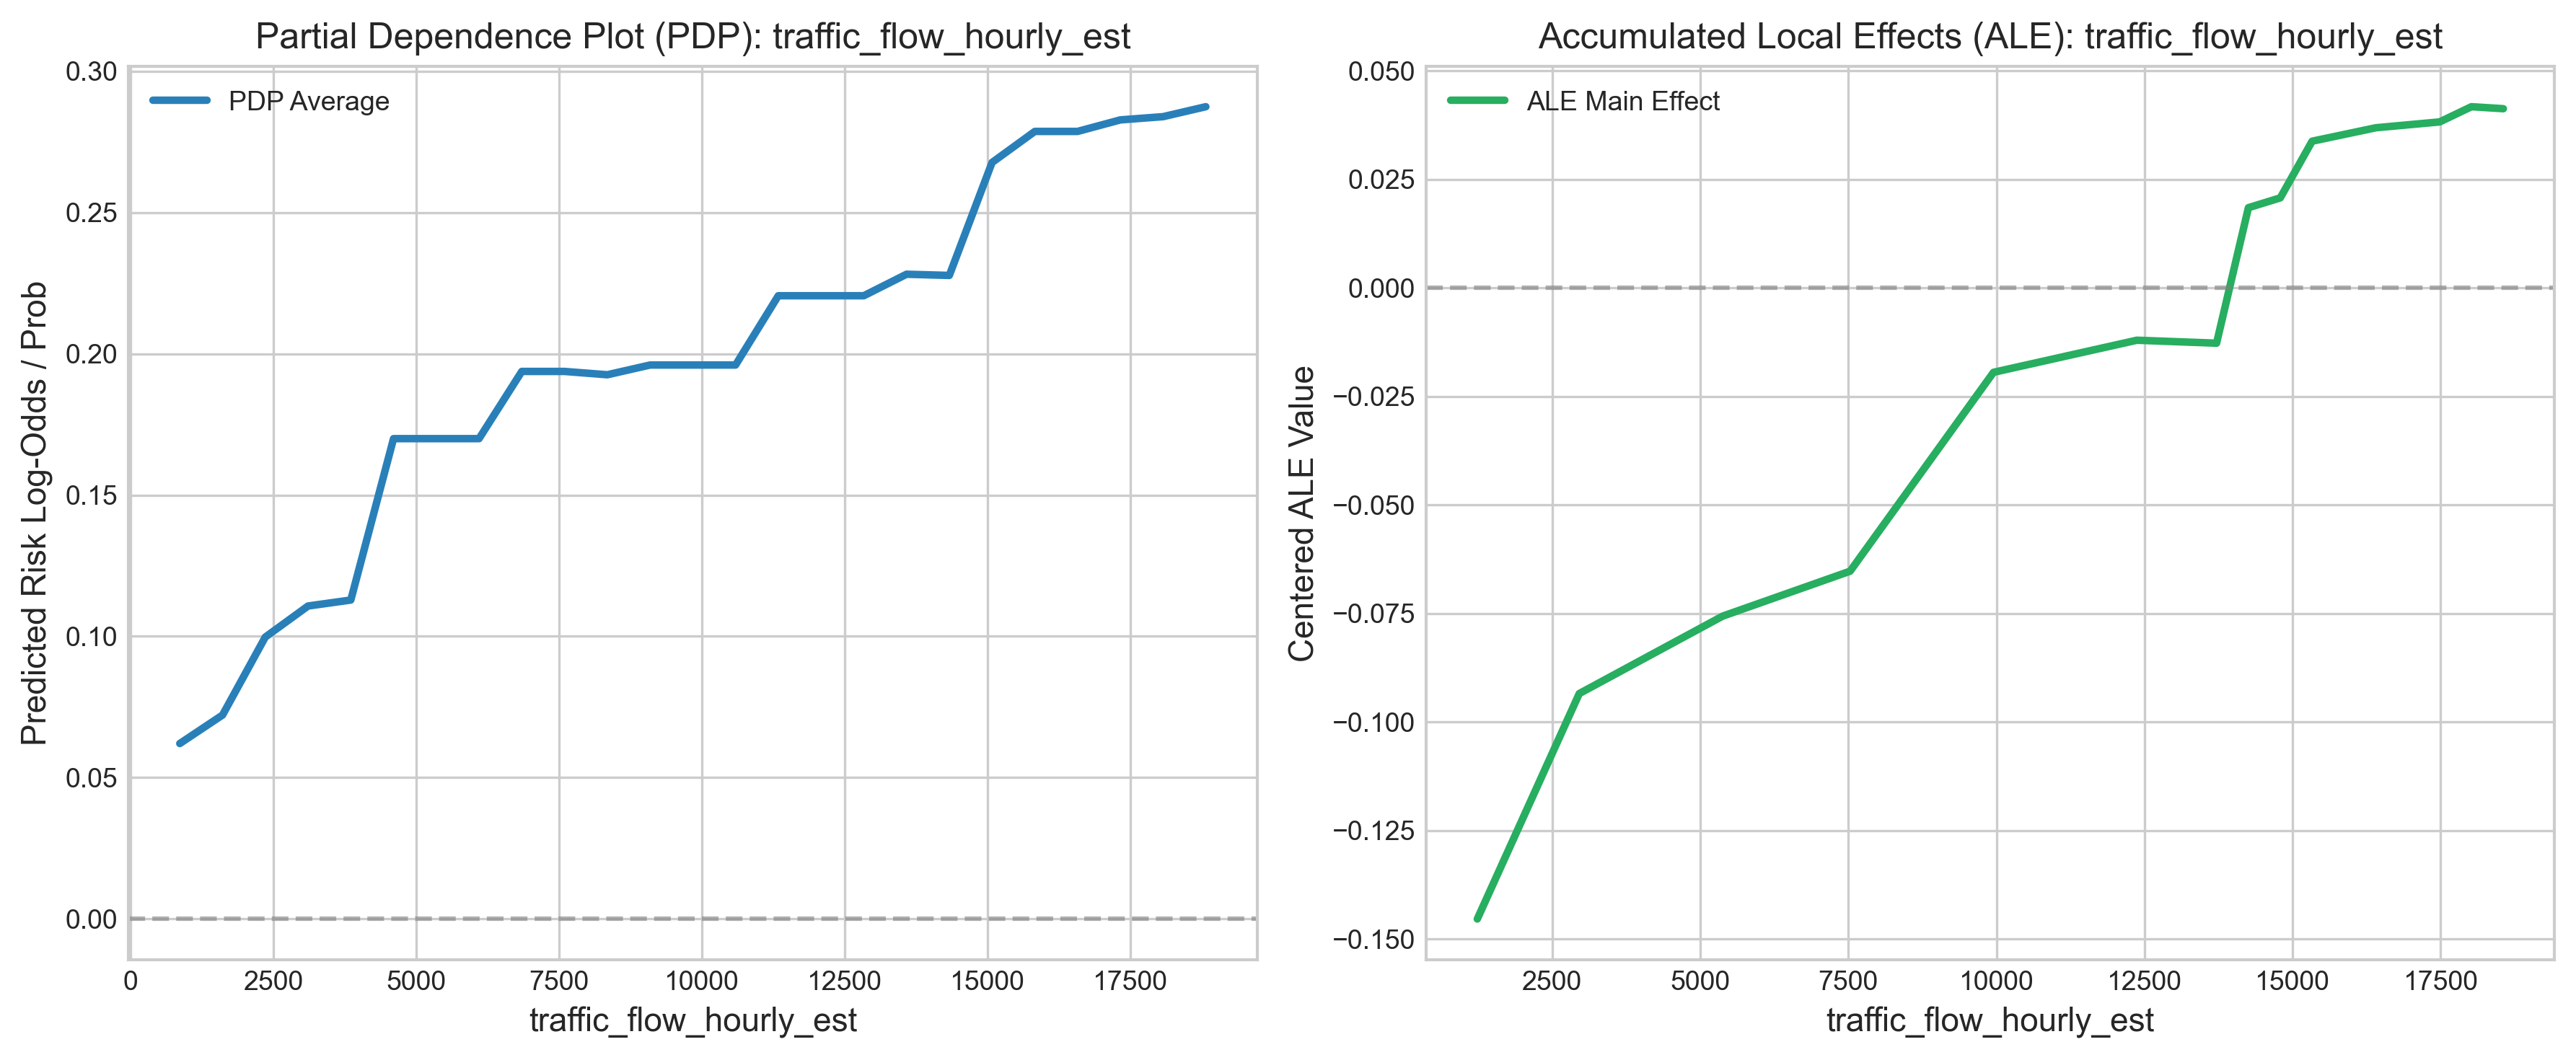

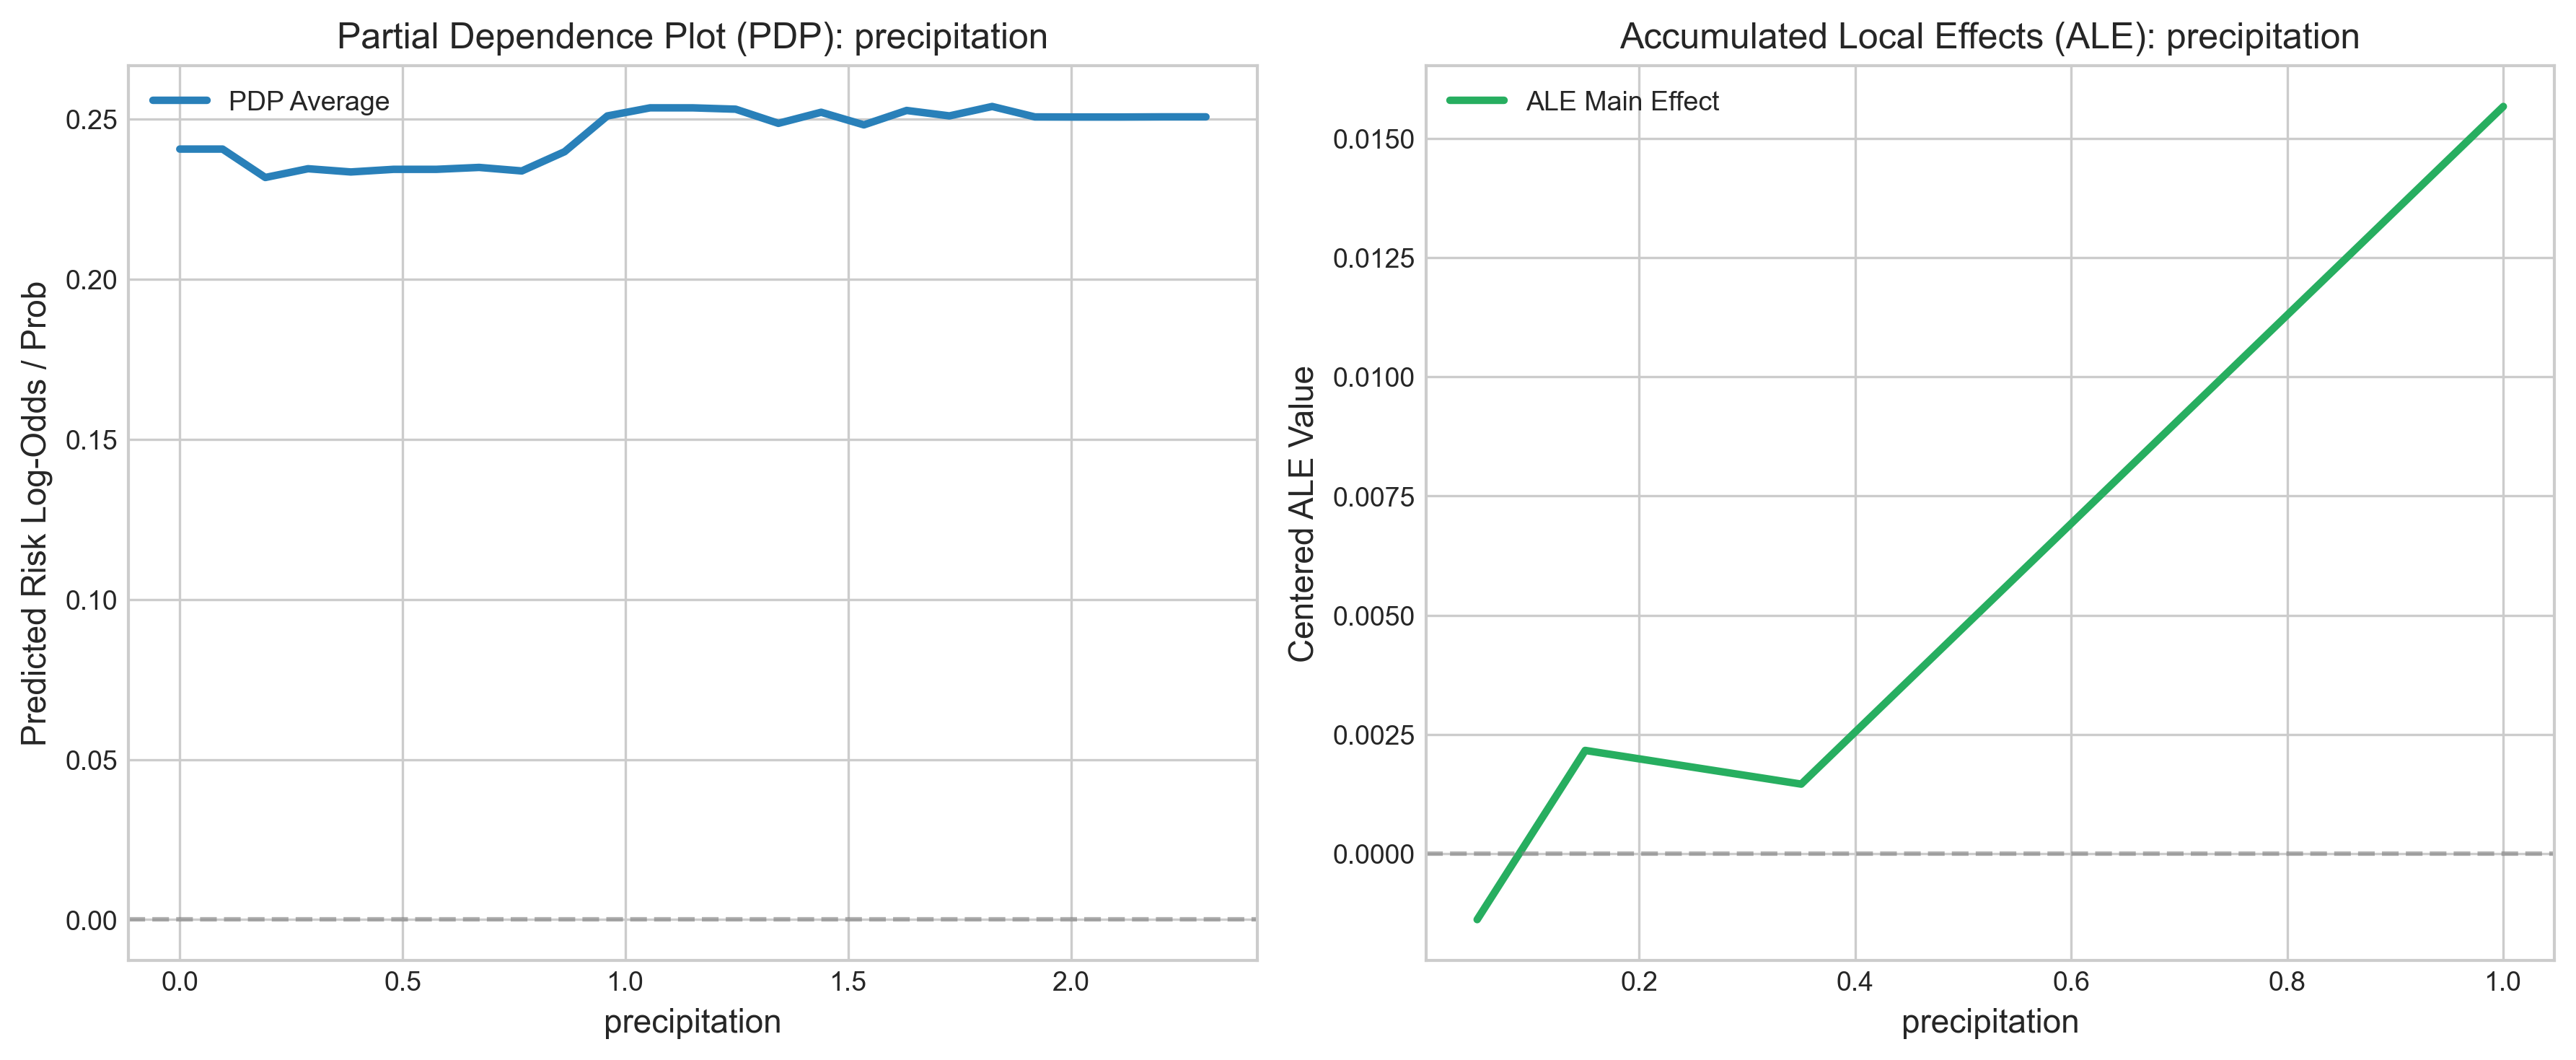

In [3]:
display(Image("figures/fig5_pdp_ale_traffic_flow_hourly_est.png"))
display(Image("figures/fig5_pdp_ale_precipitation.png"))


### Canonical Local Waterfall Cases
Six local cases represent high risk TP, low risk TN, borderline, false positive, false negative, and extreme weather.


In [4]:
with open("results/shap/local_waterfall_cases.json") as f:
    cases = json.load(f)
for k, v in cases.items():
    print(f"Case {k}: Predicted Risk={v['prob']:.3f}, True Label={v['true_label']}")


Case typical_high_risk_tp: Predicted Risk=0.584, True Label=1
Case typical_low_risk_tn: Predicted Risk=0.008, True Label=0
Case borderline_case: Predicted Risk=0.501, True Label=1
Case hard_false_positive: Predicted Risk=0.501, True Label=0
Case hard_false_negative: Predicted Risk=0.010, True Label=1
Case extreme_weather_case: Predicted Risk=0.323, True Label=1
